# Part 1: Exploratory Data Analysis

Dataset: Adult Income, OpenML version 2. The goal is to explore the data before training models. This notebook uses the full dataset only for descriptive analysis. Model training and testing are done separately in `02_models.ipynb`.

## Setup and data loading

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

FixedSeed = 42
random.seed(FixedSeed)
np.random.seed(FixedSeed)

Dataset = fetch_openml(name="adult", version=2, as_frame=True)
InputFeatures = Dataset.data.copy()
TargetVariable = Dataset.target.copy()

FullDataFrame = InputFeatures.copy()
FullDataFrame["target"] = TargetVariable
FullDataFrame["IsHighIncome"] = (TargetVariable == ">50K").astype(int)

print("Rows loaded:", len(FullDataFrame))
print("Income classes:")
print(TargetVariable.value_counts())

Rows loaded: 48842
Income classes:
class
<=50K    37155
>50K     11687
Name: count, dtype: int64


## Q1: Dataset size and types

We count rows and features and list numerical and categorical columns.

In [2]:
TotalRows = len(InputFeatures)
TotalColumns = len(InputFeatures.columns)
NumericColumns = InputFeatures.select_dtypes(include="number").columns.tolist()
CategoricalColumns = []

for Column in InputFeatures.columns:
    if Column not in NumericColumns:
        CategoricalColumns.append(Column)

print("Rows:", TotalRows)
print("Features:", TotalColumns)
print("Numeric columns:", NumericColumns)
print("Categorical columns:", CategoricalColumns)

Rows: 48842
Features: 14
Numeric columns: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical columns: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


## Q2: Missing values

The OpenML loader can convert original `?` markers into `NaN`. We count actual missing values and remaining literal `?` strings separately.

In [3]:
NaNCounts = InputFeatures.isna().sum()
QuestionCounts = pd.Series(0, index=InputFeatures.columns)

for Column in InputFeatures.columns:
    Values = InputFeatures[Column].astype("string").str.strip()
    QuestionCounts[Column] = (Values == "?").sum()

MissingTable = pd.DataFrame()
MissingTable["NaN"] = NaNCounts
MissingTable["Question mark"] = QuestionCounts
MissingTable["Total"] = MissingTable["NaN"] + MissingTable["Question mark"]

print("Columns with missing values:")
display(MissingTable[MissingTable["Total"] > 0])
print("All NaN values:", NaNCounts.sum())
print("All literal question marks:", QuestionCounts.sum())

Columns with missing values:


,NaN,Question mark,Total
workclass,2799,0,2799
occupation,2809,0,2809
native-country,857,0,857


All NaN values: 6465
All literal question marks: 0


**Q2 observation:** The OpenML dataset has 2,799 missing `workclass` values, 2,809 missing `occupation` values, and 857 missing `native-country` values. The current loaded data contains 6,465 `NaN` values and no remaining literal `?` strings. This is a property of the loaded OpenML representation, not proof that the raw source had no `?` markers.

## Q3: Income class balance

We compare the two classes. A classifier always choosing the majority class can have good accuracy even when it never identifies high-income people.

In [4]:
ClassCounts = TargetVariable.value_counts()
ClassPercent = ClassCounts / len(TargetVariable) * 100

ClassTable = pd.DataFrame()
ClassTable["Count"] = ClassCounts
ClassTable["Percent"] = ClassPercent.round(2)

display(ClassTable)

BaselineAccuracy = ClassCounts.max() / len(TargetVariable)
print("Majority-class accuracy:", round(BaselineAccuracy * 100, 2), "%")

,Count,Percent
class,,
<=50K,37155,76.07
>50K,11687,23.93


Majority-class accuracy: 76.07 %


**Q3 observation:** The majority class is `<=50K` (76.07%). Accuracy alone is insufficient on an imbalanced dataset, because a model may ignore the smaller class. In the modeling notebook we will also use precision, recall, F1, and ROC AUC, calculated on validation folds or test data.

## Q4: Visualizations

First, we plot distributions of age, working hours, and numerical education level.

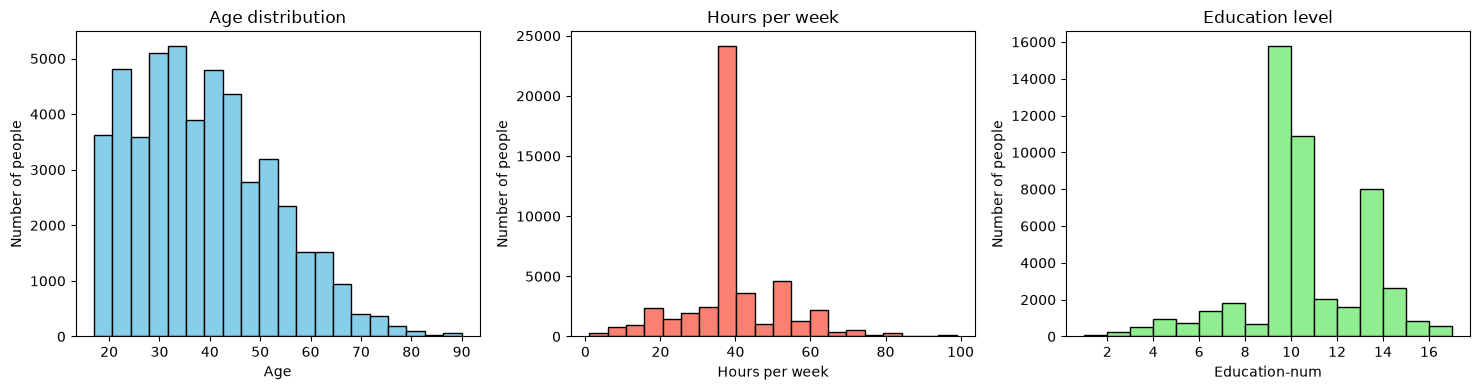

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(FullDataFrame["age"], bins=20, color="skyblue", edgecolor="black")
axes[0].set_title("Age distribution")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Number of people")

axes[1].hist(FullDataFrame["hours-per-week"], bins=20, color="salmon", edgecolor="black")
axes[1].set_title("Hours per week")
axes[1].set_xlabel("Hours per week")
axes[1].set_ylabel("Number of people")

axes[2].hist(FullDataFrame["education-num"], bins=range(1, 18), color="lightgreen", edgecolor="black")
axes[2].set_title("Education level")
axes[2].set_xlabel("Education-num")
axes[2].set_ylabel("Number of people")

plt.tight_layout()
plt.show()

Next, we compare the share of people earning more than 50K. Education categories are ordered by `education-num`. Hours are integer values, so the bins below correspond to their displayed labels.

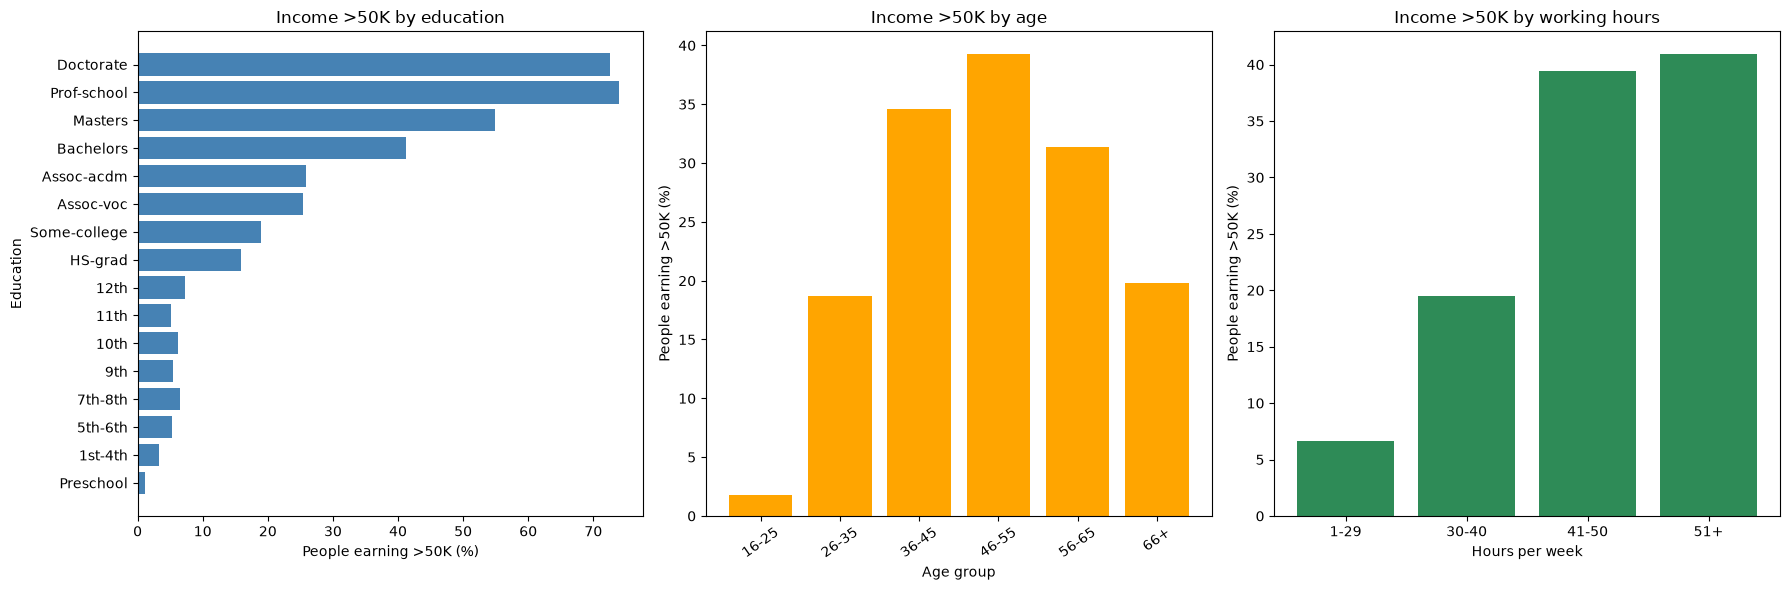

High-income share by hours group (%):
hours-per-week
1-29      6.67
30-40    19.53
41-50    39.46
51+      40.90
Name: IsHighIncome, dtype: float64


In [6]:
EducationOrder = FullDataFrame.groupby("education", observed=True)["education-num"].median()
EducationOrder = EducationOrder.sort_values().index
EducationShare = FullDataFrame.groupby("education", observed=True)["IsHighIncome"].mean()
EducationShare = EducationShare.reindex(EducationOrder) * 100

AgeGroups = pd.cut(
    FullDataFrame["age"],
    bins=[15, 25, 35, 45, 55, 65, np.inf],
    labels=["16-25", "26-35", "36-45", "46-55", "56-65", "66+"]
)
AgeShare = FullDataFrame.groupby(AgeGroups, observed=False)["IsHighIncome"].mean() * 100

HoursGroups = pd.cut(
    FullDataFrame["hours-per-week"],
    bins=[0, 29, 40, 50, np.inf],
    labels=["1-29", "30-40", "41-50", "51+"]
)
HoursShare = FullDataFrame.groupby(HoursGroups, observed=False)["IsHighIncome"].mean() * 100

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].barh(EducationShare.index.astype(str), EducationShare.values, color="steelblue")
axes[0].set_title("Income >50K by education")
axes[0].set_xlabel("People earning >50K (%)")
axes[0].set_ylabel("Education")

axes[1].bar(AgeShare.index.astype(str), AgeShare.values, color="orange")
axes[1].set_title("Income >50K by age")
axes[1].set_xlabel("Age group")
axes[1].set_ylabel("People earning >50K (%)")
axes[1].tick_params(axis="x", rotation=35)

axes[2].bar(HoursShare.index.astype(str), HoursShare.values, color="seagreen")
axes[2].set_title("Income >50K by working hours")
axes[2].set_xlabel("Hours per week")
axes[2].set_ylabel("People earning >50K (%)")

plt.tight_layout()
plt.show()

print("High-income share by hours group (%):")
print(HoursShare.round(2))

**Q4 observation:** The largest working-hours peak is near 40 hours a week. In this dataset, higher levels of education and certain age and working-hour groups have higher shares of income above 50K. These are observed relationships, not evidence that one feature causes the income difference.

## Q5: Feature usefulness

`capital-gain` describes reported gains from assets, not wages or direct salary. We compare its two groups using counts and percentages. `education` and `education-num` describe the same education levels in different forms.

In [7]:
FullDataFrame["CapitalGroup"] = "capital-gain = 0"
FullDataFrame.loc[FullDataFrame["capital-gain"] > 0, "CapitalGroup"] = "capital-gain > 0"

CapitalCount = FullDataFrame.groupby("CapitalGroup")["IsHighIncome"].size()
CapitalHigh = FullDataFrame.groupby("CapitalGroup")["IsHighIncome"].sum()
CapitalPercent = CapitalHigh / CapitalCount * 100

CapitalTable = pd.DataFrame()
CapitalTable["People"] = CapitalCount
CapitalTable["Income >50K"] = CapitalHigh
CapitalTable["Income >50K (%)"] = CapitalPercent.round(2)

display(CapitalTable)

EducationMapping = FullDataFrame.groupby("education", observed=True)["education-num"].nunique()
print("Number of education-num values for each education category:")
print(EducationMapping)

,People,Income >50K,Income >50K (%)
CapitalGroup,,,
capital-gain = 0,44807,9196,20.52
capital-gain > 0,4035,2491,61.73


Number of education-num values for each education category:
education
10th            1
11th            1
12th            1
1st-4th         1
5th-6th         1
7th-8th         1
9th             1
Assoc-acdm      1
Assoc-voc       1
Bachelors       1
Doctorate       1
HS-grad         1
Masters         1
Preschool       1
Prof-school     1
Some-college    1
Name: education-num, dtype: int64


**Q5 observation:** The share earning over 50K is 61.73% for people with `capital-gain > 0` and 20.52% for those with `capital-gain = 0`. Each named education category has one `education-num` value, so the two columns contain overlapping information. `fnlwgt` is a census sampling weight, not an individual income measurement.

## Q6: Fairness and ethics

We calculate income proportions for the `sex` and `race` groups. These are dataset statistics, not measurements of whether a trained model treats groups fairly.

In [8]:
SexCount = FullDataFrame.groupby("sex", observed=True)["IsHighIncome"].size()
SexHigh = FullDataFrame.groupby("sex", observed=True)["IsHighIncome"].sum()

SexTable = pd.DataFrame()
SexTable["People"] = SexCount
SexTable["Income >50K"] = SexHigh
SexTable["Income >50K (%)"] = (SexHigh / SexCount * 100).round(2)

RaceCount = FullDataFrame.groupby("race", observed=True)["IsHighIncome"].size()
RaceHigh = FullDataFrame.groupby("race", observed=True)["IsHighIncome"].sum()

RaceTable = pd.DataFrame()
RaceTable["People"] = RaceCount
RaceTable["Income >50K"] = RaceHigh
RaceTable["Income >50K (%)"] = (RaceHigh / RaceCount * 100).round(2)

print("Income by sex:")
display(SexTable)

print("Income by race:")
display(RaceTable)

Income by sex:


,People,Income >50K,Income >50K (%)
sex,,,
Female,16192,1769,10.93
Male,32650,9918,30.38


Income by race:


,People,Income >50K,Income >50K (%)
race,,,
Amer-Indian-Eskimo,470,55,11.70
Asian-Pac-Islander,1519,409,26.93
Black,4685,566,12.08
Other,406,50,12.32
White,41762,10607,25.40


**Q6 observation:** In this dataset, 30.38% of males and 10.93% of females have incomes over 50K. The shares are 25.40% for White individuals, 12.08% for Black individuals, and 26.93% for Asian-Pac-Islander individuals. These numbers show differences in the dataset but do not prove that a trained model is discriminatory. Removing `sex` would not remove every potential fairness risk, because other variables such as `occupation` and `relationship` could act as proxy features.

## Conclusions

- **Q1:** The Adult dataset contains 48,842 rows and 14 input features.
- **Q2:** Missing values are counted separately as `NaN` and literal `?` values.
- **Q3:** The majority class has 76.07% of the records, so accuracy alone is not enough.
- **Q4:** Education, age, and working hours show different observed high-income shares.
- **Q5:** Positive capital gains are associated with a larger high-income share, and the two education columns overlap.
- **Q6:** Income proportions differ across demographic groups; model-level fairness would require separate evaluation of prediction errors.

**How to run:** Open this notebook in Jupyter, select Python 3, choose Restart and Run All, and save with outputs. No model is fitted in this notebook. The descriptive results should not be used to make real decisions about individuals.